In [ ]:
# Setup and Dependencies
!pip install -q torchfile
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import wandb
import numpy as np
import torchfile
import matplotlib.pyplot as plt
import cv2

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
wandb.login(key="c02566a740b6ae5bd072dcf4ae32d9f735e9fa0b")

# Download model weights (if not already present)
!wget -q http://www.robots.ox.ac.uk/~vgg/software/vgg_face/src/vgg_face_torch.tar.gz
!tar -xvf vgg_face_torch.tar.gz
!mv vgg_face_torch/VGG_FACE.t7 ./
!mv vgg_face_torch/names.txt ./
!mv vgg_face_torch/ak.png ./

print("Setup complete.")

  Preparing metadata (setup.py) ... done
Device: cpu


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kokashreya (kokashreya-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


vgg_face_torch/
vgg_face_torch/._ak.png
vgg_face_torch/ak.png
vgg_face_torch/._COPYING
vgg_face_torch/COPYING
vgg_face_torch/demo.lua
vgg_face_torch/names.txt
vgg_face_torch/._README
vgg_face_torch/README
vgg_face_torch/VGG_FACE.t7
Setup complete.


In [ ]:
# Define VGG_16 Model Class
class VGG_16(nn.Module):
    def __init__(self):
        super().__init__()
        self.block_size = [2, 2, 3, 3, 3]
        self.conv_1_1 = nn.Conv2d(3, 64, 3, stride=1, padding=1)
        self.conv_1_2 = nn.Conv2d(64, 64, 3, stride=1, padding=1)
        self.conv_2_1 = nn.Conv2d(64, 128, 3, stride=1, padding=1)
        self.conv_2_2 = nn.Conv2d(128, 128, 3, stride=1, padding=1)
        self.conv_3_1 = nn.Conv2d(128, 256, 3, stride=1, padding=1)
        self.conv_3_2 = nn.Conv2d(256, 256, 3, stride=1, padding=1)
        self.conv_3_3 = nn.Conv2d(256, 256, 3, stride=1, padding=1)
        self.conv_4_1 = nn.Conv2d(256, 512, 3, stride=1, padding=1)
        self.conv_4_2 = nn.Conv2d(512, 512, 3, stride=1, padding=1)
        self.conv_4_3 = nn.Conv2d(512, 512, 3, stride=1, padding=1)
        self.conv_5_1 = nn.Conv2d(512, 512, 3, stride=1, padding=1)
        self.conv_5_2 = nn.Conv2d(512, 512, 3, stride=1, padding=1)
        self.conv_5_3 = nn.Conv2d(512, 512, 3, stride=1, padding=1)
        self.fc6 = nn.Linear(512 * 7 * 7, 4096)
        self.fc7 = nn.Linear(4096, 4096)
        self.fc8 = nn.Linear(4096, 2)  # Modified for binary classification

    def load_weights(self, path="VGG_FACE.t7"):
        model = torchfile.load(path)
        counter = 1
        block = 1
        for i, layer in enumerate(model.modules):
            if layer.weight is not None:
                if block <= 5:
                    self_layer = getattr(self, "conv_%d_%d" % (block, counter))
                    counter += 1
                    if counter > self.block_size[block - 1]:
                        counter = 1
                        block += 1
                elif block == 6:
                    self_layer = self.fc6
                    block += 1
                elif block == 7:
                    self_layer = self.fc7
                    block += 1
                elif block == 8:
                    break  # Skip fc8
                self_layer.weight.data[...] = torch.tensor(layer.weight).view_as(self_layer.weight)[...]
                self_layer.bias.data[...] = torch.tensor(layer.bias).view_as(self_layer.bias)[...]
        # Initialize fc8 weights and biases randomly
        nn.init.xavier_uniform_(self.fc8.weight)
        nn.init.zeros_(self.fc8.bias)

    def forward(self, x):
        x = F.relu(self.conv_1_1(x))
        x = F.relu(self.conv_1_2(x))
        x = F.max_pool2d(x, 2, 2)
        x = F.relu(self.conv_2_1(x))
        x = F.relu(self.conv_2_2(x))
        x = F.max_pool2d(x, 2, 2)
        x = F.relu(self.conv_3_1(x))
        x = F.relu(self.conv_3_2(x))
        x = F.relu(self.conv_3_3(x))
        x = F.max_pool2d(x, 2, 2)
        x = F.relu(self.conv_4_1(x))
        x = F.relu(self.conv_4_2(x))
        x = F.relu(self.conv_4_3(x))
        x = F.max_pool2d(x, 2, 2)
        x = F.relu(self.conv_5_1(x))
        x = F.relu(self.conv_5_2(x))
        x = F.relu(self.conv_5_3(x))
        x = F.max_pool2d(x, 2, 2)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc6(x))
        x = F.dropout(x, 0.5, self.training)
        x = F.relu(self.fc7(x))
        x = F.dropout(x, 0.5, self.training)
        return self.fc8(x)

print("VGG_16 model defined.")

VGG_16 model defined.


In [ ]:
# Data Preparation
# Define transforms
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
from google.colab import files
uploaded = files.upload()
if list(uploaded.keys())[0].endswith('.zip'):
    !unzip -q "{list(uploaded.keys())[0]}"  # Unzips to current directory
    # print(f"Files unzipped: {os.listdir()}")
else:
    print("Assuming files are already in place.")
# !unzip -q final.zip -d final


Saving final.zip to final.zip


In [ ]:
train_dataset = ImageFolder(root='final/train', transform=train_transform)
val_dataset = ImageFolder(root='final/val', transform=val_transform)
test_dataset = ImageFolder(root='final/test', transform=test_transform)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Training samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}")

Training samples: 783, Validation samples: 101


In [ ]:
# Model Initialization and Fine-Tuning Setup
import torch.optim as optim

model = VGG_16()
model.load_weights("VGG_FACE.t7")

# Freeze all layers except the final classifier
for param in model.parameters():
    param.requires_grad = False
for param in model.fc8.parameters():
    param.requires_grad = True

# Move to device
model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc8.parameters(), lr=1e-4, weight_decay=1e-4)

# Initialize wandb
wandb.init(project="face_recognition_vggface", config={
    "learning_rate": 1e-4,
    "batch_size": 32,
    "epochs": 10
})

print("Model and training setup complete.")

Model and training setup complete.


In [ ]:
# Training and Validation Functions
def train(model, train_loader, criterion, optimizer, epoch):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for i, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        if i % 10 == 9:
            print(f'Epoch [{epoch+1}], Step [{i+1}], Loss: {running_loss/10:.4f}')
            running_loss = 0.0
    accuracy = 100 * correct / total
    train_loss = running_loss / len(train_loader)  # Average loss for the epoch
    wandb.log({"train_loss": train_loss, "train_accuracy": accuracy})
    return accuracy, train_loss

def validate(model, val_loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    val_loss = running_loss / len(val_loader)
    wandb.log({"val_accuracy": accuracy, "val_loss": val_loss})
    return accuracy, val_loss

print("Training and validation functions defined.")

Training and validation functions defined.


Epoch [1], Step [10], Loss: 0.6984
Epoch [1], Step [20], Loss: 0.6846
Epoch [1/10], Train Acc: 55.43%, Val Acc: 74.26%, Train Loss: 0.1352, Val Loss: 0.6653
Epoch [2], Step [10], Loss: 0.6655
Epoch [2], Step [20], Loss: 0.6587
Epoch [2/10], Train Acc: 74.46%, Val Acc: 78.22%, Train Loss: 0.1286, Val Loss: 0.6367
Epoch [3], Step [10], Loss: 0.6439
Epoch [3], Step [20], Loss: 0.6314
Epoch [3/10], Train Acc: 77.27%, Val Acc: 80.20%, Train Loss: 0.1248, Val Loss: 0.6097
Epoch [4], Step [10], Loss: 0.6187
Epoch [4], Step [20], Loss: 0.6131
Epoch [4/10], Train Acc: 78.16%, Val Acc: 81.19%, Train Loss: 0.1209, Val Loss: 0.5854
Epoch [5], Step [10], Loss: 0.5932
Epoch [5], Step [20], Loss: 0.5933
Epoch [5/10], Train Acc: 80.08%, Val Acc: 81.19%, Train Loss: 0.1153, Val Loss: 0.5639
Epoch [6], Step [10], Loss: 0.5791
Epoch [6], Step [20], Loss: 0.5750
Epoch [6/10], Train Acc: 84.29%, Val Acc: 83.17%, Train Loss: 0.1102, Val Loss: 0.5439
Epoch [7], Step [10], Loss: 0.5645
Epoch [7], Step [20], L

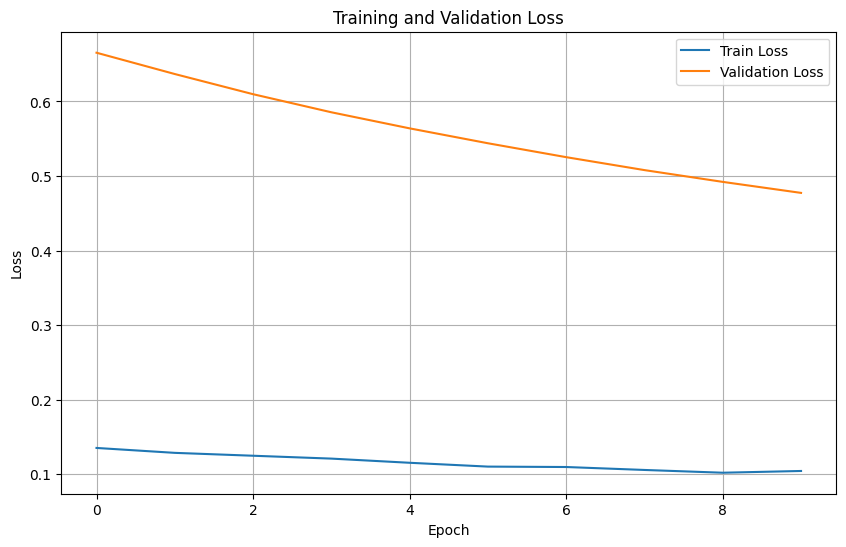

train_accuracy,▁▅▆▆▆▇▇▇▇█
train_loss,█▇▆▅▄▃▃▂▁▁
val_accuracy,▁▄▅▅▅▇▇▇██
val_loss,█▇▆▅▄▃▃▂▂▁
train_accuracy,87.35632
train_loss,0.10434
val_accuracy,85.14851
val_loss,0.47731


Training completed. Best model saved.


In [ ]:
# Training Loop
num_epochs = 10
best_val_acc = 0.0
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    train_acc, train_loss = train(model, train_loader, criterion, optimizer, epoch)  # Unpack train loss
    val_acc, val_loss = validate(model, val_loader, criterion)  # Unpack val loss
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f'Epoch [{epoch+1}/{num_epochs}], Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_vggface_model.pth")

# Plot train and validation loss
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

wandb.finish()
print("Training completed. Best model saved.")

len(all_labels) 40
len(correct) 33
Test Loss: 0.5636
Test Accuracy: 82.50%
Precision: 0.71
Recall: 1.00
F1-score: 0.83
Confusion Matrix:


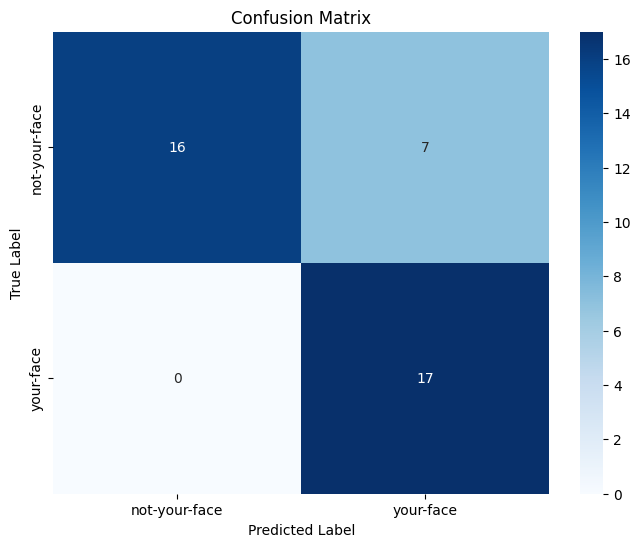

f1_score,▁
precision,▁
recall,▁
test_accuracy,▁
test_loss,▁
f1_score,0.82927
precision,0.70833
recall,1
test_accuracy,82.5
test_loss,0.56365


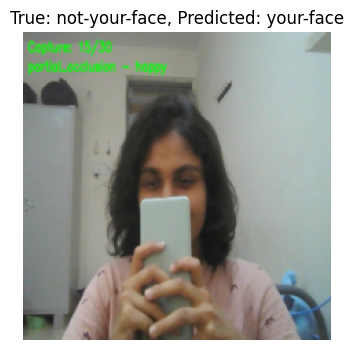

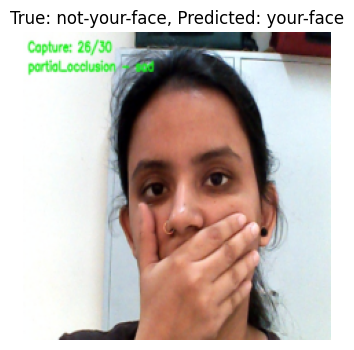

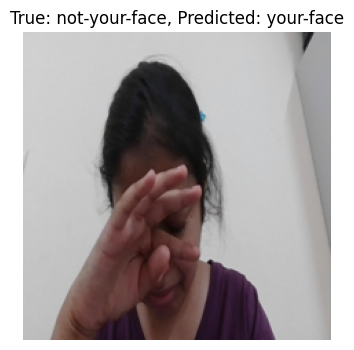

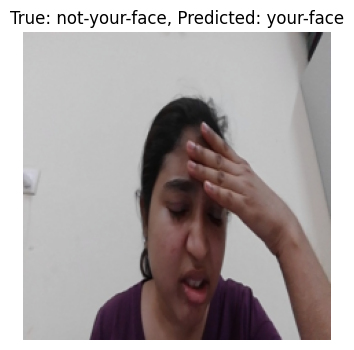

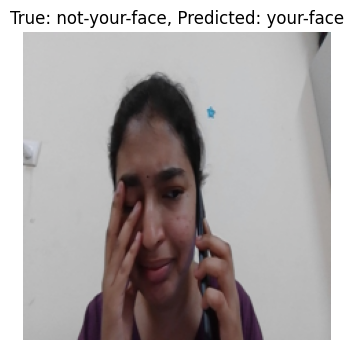

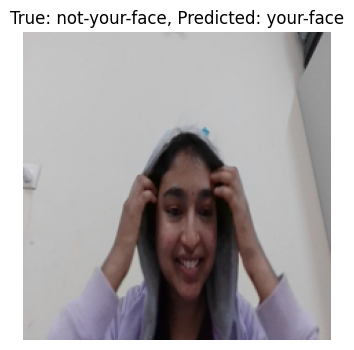

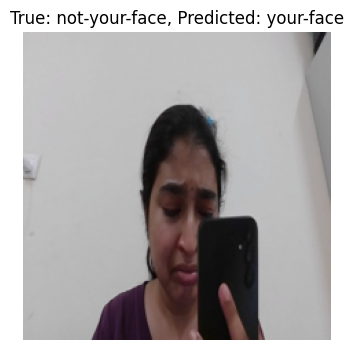

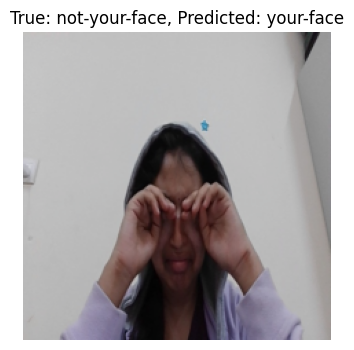

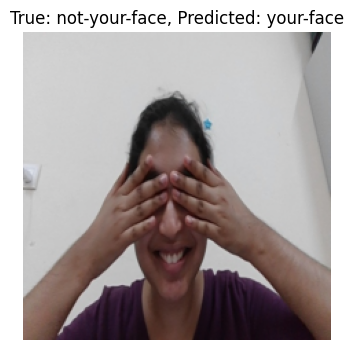

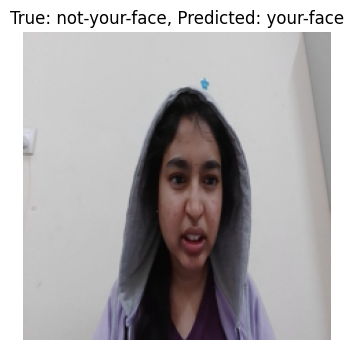

Total misclassified images: 10 out of 40


In [ ]:
# Evaluate on test set
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

criterion = nn.CrossEntropyLoss()
running_loss = 0.0
all_predictions = []
all_labels = []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = running_loss / len(test_loader)
test_accuracy = 100 * sum(1 for p, l in zip(all_predictions, all_labels) if p == l) / len(all_labels)
print('len(all_labels)', len(all_labels))
print('len(correct)', sum(1 for p, l in zip(all_predictions, all_labels) if p == l))
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')
conf_matrix = confusion_matrix(all_labels, all_predictions)

print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.2f}%')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1-score: {f1:.2f}')
print('Confusion Matrix:')

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['not-your-face', 'your-face'], yticklabels=['not-your-face', 'your-face'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Log to wandb
wandb.init(project="face_recognition_vggface", config={"phase": "test"})
wandb.log({"test_loss": test_loss, "test_accuracy": test_accuracy, "precision": precision, "recall": recall, "f1_score": f1})
wandb.finish()

# Display each test image with its label (unchanged)
# Display each test image with its label
label_map = {0: "not-your-face", 1: "your-face"}  # Map numeric labels to names
count = 0
total = 0
for i, (image, label) in enumerate(test_dataset):
    image = image.numpy().transpose((1, 2, 0))  # Convert from CHW to HWC
    image = image * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Reverse normalization
    image = np.clip(image, 0, 1)  # Ensure values are in [0, 1]

    model.eval()
    with torch.no_grad():
        # Convert NumPy array to tensor and prepare for model
        input_tensor = torch.from_numpy(image.transpose(2, 0, 1)).float().unsqueeze(0).to(device)  # CHW, add batch dim
        output = model(input_tensor)
        _, predicted = torch.max(output, 1)

    true_label = label_map[label]
    pred_label = label_map[predicted.item()]
    total += 1
    if true_label != pred_label:
        count += 1
        plt.figure(figsize=(4, 4))
        plt.imshow(image)
        plt.title(f'True: {true_label}, Predicted: {pred_label}')
        plt.axis('off')
        plt.show()

print(f"Total misclassified images: {count} out of {total}")

In [ ]:
import cv2
import numpy as np

def generate_prediction_video(test_loader, model, class_names=['Not You', 'You'], output_path='output_video.mp4', max_frames=50):
    model.eval()
    images = []
    preds = []
    truths = []

    # Collect images, predictions, and true labels
    with torch.no_grad():
        for inputs, labels in test_loader:  # Only inputs and labels from test_loader
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            images.extend(inputs.cpu().numpy())  # Store images
            preds.extend(predicted.cpu().numpy())  # Store predictions
            truths.extend(labels.cpu().numpy())  # Store true labels

    # Initialize video writer
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), 2, (224, 224))

    # Process up to max_frames
    for i in range(min(len(images), max_frames)):
        # Denormalize image
        img = images[i].transpose(1, 2, 0)  # Change from (C, H, W) to (H, W, C)
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Reverse normalization
        img = np.clip(img * 255, 0, 255).astype(np.uint8)  # Scale to 0-255 and convert to uint8
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)  # Convert to BGR for OpenCV

        # Add prediction and true label text
        cv2.putText(img, f"Pred: {class_names[preds[i]]}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        cv2.putText(img, f"True: {class_names[truths[i]]}", (10, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

        # Write frame to video
        out.write(img)

    # Release video writer
    out.release()
    print(f"Video saved to {output_path}")

In [ ]:
# Generate the prediction video
generate_prediction_video(test_loader, model, class_names=['not-your-face', 'your-face'],
                         output_path='face_recognition_output_vggface.mp4', max_frames=50)

Video saved to face_recognition_output_vggface.mp4


In [ ]:
import cv2
import numpy as np
import torch
from google.colab import files
from IPython.display import Video

def generate_unlock_simulation_video(test_loader, model, class_names=['not-your-face', 'your-face'],
                                   output_path='unlock_simulation_vggface.mp4', max_frames=50):
    """
    Generate a video simulating a phone unlock system using test images.
    Displays 'Unlocked' for 'your-face' (class 0) and 'Locked' for 'not-your-face' (class 1).

    Args:
        test_loader: DataLoader for test images
        model: Trained VGGFace model
        class_names: List of class names [not-your-face, your-face]
        output_path: Path to save the output video
        max_frames: Maximum number of frames to include in the video
    """
    model.eval()
    images = []
    preds = []
    truths = []

    # Collect images, predictions, and true labels
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            images.extend(inputs.cpu().numpy())  # Store images
            preds.extend(predicted.cpu().numpy())  # Store predictions
            truths.extend(labels.cpu().numpy())  # Store true labels

    # Initialize video writer (224x224 resolution, 2 FPS)
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), 2, (224, 224))

    # Process up to max_frames
    for i in range(min(len(images), max_frames)):
        # Denormalize image
        img = images[i].transpose(1, 2, 0)  # Change from (C, H, W) to (H, W, C)
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Reverse normalization
        img = np.clip(img * 255, 0, 255).astype(np.uint8)  # Scale to 0-255 and convert to uint8
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)  # Convert to BGR for OpenCV

        # Determine unlock status: Unlocked if predicted as 'your-face' (class 0), Locked otherwise
        status = "Unlocked" if preds[i] == 1 else "Locked"
        status_color = (0, 255, 0) if preds[i] == 1 else (0, 0, 255)  # Green for Unlocked, Red for Locked

        # Add status text and true label to the image
        cv2.putText(img, f"Status: {status}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, status_color, 2)
        cv2.putText(img, f"True: {class_names[truths[i]]}", (10, 60),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

        # Write frame to video
        out.write(img)

    # Release video writer
    out.release()
    print(f"Unlock simulation video saved to {output_path}")

# Verify class indices
print("Class indices:", test_dataset.class_to_idx)

# Run the unlock simulation
generate_unlock_simulation_video(test_loader, model, class_names=['not-your-face', 'your-face'],
                                output_path='unlock_simulation_vggface.mp4', max_frames=50)

# Display the video in Colab
Video('unlock_simulation_vggface.mp4', embed=True, width=400)

# Provide a download link for the video
files.download('unlock_simulation_vggface.mp4')

Class indices: {'class_0': 0, 'class_1': 1}
Unlock simulation video saved to unlock_simulation_vggface.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset - https://drive.google.com/file/d/17a3TAZT-_s08FBGRpCAGwnmIbZgwjlMq/view?usp=drive_link